# AA3 · Parcial II · Cuaderno 2: Embeddings
**Alumno:** Santiago Romo Rubio
**Datos:** reseñas de Amazon en español, [`SetFit/amazon_reviews_multi_es`](https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es) (Hugging Face), clasificadas en 5 clases según sus estrellas

Conjunto contra secuencia en español (Práctica 4, ejercicio final, Parte 1): una **bolsa de bigramas** (Bloque 4) contra **Embedding + Bi-LSTM** (Bloque 5), con las mismas reglas para los dos.

## 1. Datos
**Entorno.** El mismo de la Práctica 4: en Colab, Keras usa TensorFlow; en Windows nativo, PyTorch. `TextVectorization` y `tf.data` necesitan TensorFlow con cualquier motor.

In [1]:
import importlib.util
import os
import re
import sys
import time
import warnings

warnings.filterwarnings("ignore", message="RNN module weights")  # aviso de cuDNN con PyTorch, no afecta el resultado

EN_COLAB = importlib.util.find_spec("google.colab") is not None
EN_WSL = "microsoft" in os.uname().release.lower() if hasattr(os, "uname") else False
os.environ["KERAS_BACKEND"] = os.environ.get("KERAS_BACKEND") or ("tensorflow" if EN_COLAB or EN_WSL else "torch")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import torch
from keras import layers
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

SEED = 42
keras.utils.set_random_seed(SEED)
DIR_DATOS = "datos"
DIR_MODELOS = os.path.join("modelos", "C2")
os.makedirs(DIR_DATOS, exist_ok=True)
os.makedirs(DIR_MODELOS, exist_ok=True)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_colwidth", 200)

print(f"Python {sys.version.split()[0]} · Keras {keras.__version__} · motor {keras.backend.backend()} · TensorFlow {tf.__version__}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no disponible'}")

Python 3.11.16 · Keras 3.15.1 · motor torch · TensorFlow 2.21.0
GPU: NVIDIA GeForce GTX 1660 SUPER


**El dataset.** [`SetFit/amazon_reviews_multi_es`](https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es) es la parte en español de *Multilingual Amazon Reviews Corpus* (Keung et al., 2020): reseñas de productos de Amazon con su calificación de 1 a 5 estrellas, que el dataset guarda como etiqueta 0 a 4. Viene balanceado: 200,000 reseñas de entrenamiento (40,000 por clase), 5,000 de validación y 5,000 de prueba. Los archivos `.jsonl` se descargan una sola vez en `datos/`.

In [2]:
URL_BASE = "https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es/resolve/main"
partes = {}
for parte in ["train", "test"]:
    archivo = os.path.join(DIR_DATOS, f"amazon_es_{parte}.jsonl")
    if not os.path.exists(archivo):
        print(f"Descargando {parte}.jsonl ...")
        pd.read_json(f"{URL_BASE}/{parte}.jsonl", lines=True).to_json(archivo, orient="records", lines=True, force_ascii=False)
    partes[parte] = pd.read_json(archivo, lines=True)

CLASES = ["1 estrella", "2 estrellas", "3 estrellas", "4 estrellas", "5 estrellas"]
N_CLASES = len(CLASES)
for parte, d in partes.items():
    print(f"{parte:5s}: {len(d):,} reseñas · clases: {d['label'].value_counts().sort_index().to_dict()}")
print(f"\nTotal: {sum(len(d) for d in partes.values()):,} ejemplos · {N_CLASES} clases ({', '.join(CLASES)})")
for _, fila in partes["train"].groupby("label").head(1).sort_values("label").iterrows():
    print(f"  [{CLASES[fila['label']]}] {fila['text'][:150]}")

train: 200,000 reseñas · clases: {0: 40000, 1: 40000, 2: 40000, 3: 40000, 4: 40000}
test : 5,000 reseñas · clases: {0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000}

Total: 205,000 ejemplos · 5 clases (1 estrella, 2 estrellas, 3 estrellas, 4 estrellas, 5 estrellas)
  [1 estrella] Nada bueno se me fue ka pantalla en menos de 8 meses y no he recibido respuesta del fabricante
  [2 estrellas] Los tornillos no ajustan bien, se caen. No lo volvería a comprar
  [3 estrellas] cabe bien un móvil de 5,5 y cumple su función se hecha de menos un pequeño espacio para guardar tarjeta o efectivo seria muy útil
  [4 estrellas] Tiene buena pinta, veremos el resultado
  [5 estrellas] Es muy práctico para cuando me voy de vacaciones, ya no me tengo que preocupar de si seguirán vivas las plantas cuando vuelva. El montaje es muy senci


**División con semilla.** Como en la práctica, el 20 % del entrenamiento se separa para validación con la semilla 42 (estratificado). La **prueba** es la oficial (5,000 reseñas) y se usa **una sola vez**, al final de cada modelo. La validación oficial del dataset no se usa.

In [3]:
x_train, x_val, y_train, y_val = train_test_split(
    partes["train"]["text"].tolist(), partes["train"]["label"].to_numpy(), test_size=0.2, stratify=partes["train"]["label"], random_state=SEED
)
x_test, y_test = partes["test"]["text"].tolist(), partes["test"]["label"].to_numpy()
print(f"Entrenamiento: {len(x_train):,} · Validación: {len(x_val):,} · Prueba: {len(x_test):,}")

Entrenamiento: 160,000 · Validación: 40,000 · Prueba: 5,000


**El cociente de Google.** La regla de la Práctica 4: si $\frac{\text{muestras}}{\text{mediana de palabras por muestra}}$ es **menor que 1,500**, conviene un modelo de **conjunto** (bigramas); si es **1,500 o más**, uno de **secuencia**. Se calcula con el entrenamiento.

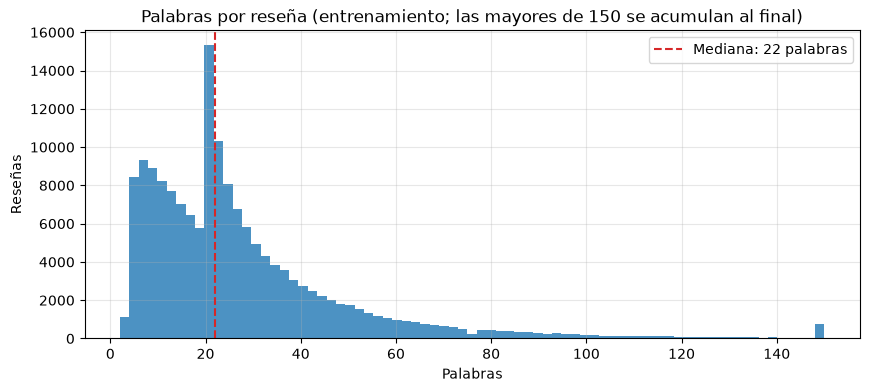

Reseñas de entrenamiento: 160,000 · mediana: 22 palabras · percentil 95: 72 · máximo: 506
Cociente = 160,000 / 22 = 7,273
Predicción de la regla: MODELO DE SECUENCIA


In [4]:
longitudes = np.array([len(t.split()) for t in x_train])
mediana = np.median(longitudes)
cociente = len(x_train) / mediana

plt.figure(figsize=(10, 4))
plt.hist(np.clip(longitudes, 0, 150), bins=75, color="tab:blue", alpha=0.8)
plt.axvline(mediana, color="tab:red", linestyle="--", label=f"Mediana: {mediana:.0f} palabras")
plt.title("Palabras por reseña (entrenamiento; las mayores de 150 se acumulan al final)")
plt.xlabel("Palabras")
plt.ylabel("Reseñas")
plt.legend()
plt.show()

print(f"Reseñas de entrenamiento: {len(x_train):,} · mediana: {mediana:.0f} palabras · percentil 95: {np.percentile(longitudes, 95):.0f} · máximo: {longitudes.max()}")
print(f"Cociente = {len(x_train):,} / {mediana:.0f} = {cociente:,.0f}")
print("Predicción de la regla:", "BIGRAMAS (modelo de conjunto)" if cociente < 1500 else "MODELO DE SECUENCIA")

> **Mi predicción, escrita antes de entrenar:** el cociente es de unos 7,300, casi cinco veces el umbral de 1,500, así que según la regla **debería ganar el modelo de secuencia** (Embedding + Bi-LSTM). Es el caso contrario a IMDb (cociente ≈ 114): aquí hay muchas reseñas y son cortas, así que la Bi-LSTM tiene datos para aprender a usar el orden («no es malo», «bueno pero…»). Espero que la diferencia sea **pequeña**, de uno o dos puntos: con 5 clases, buena parte del error está entre estrellas vecinas (4 contra 5, 1 contra 2), y eso es difícil para cualquier modelo.

**Del texto al tensor.** La estandarización por defecto de `TextVectorization` pasa a minúsculas y quita la puntuación ASCII, pero no los signos de apertura del español. `limpiar()` los cambia por un espacio antes de vectorizar, para que «¿qué» y «qué» sean el mismo token. Los **vocabularios se construyen solo con el entrenamiento** (`adapt()`).

In [5]:
BATCH = 32
LARGO_SECUENCIA = 120  # el 95 % de las reseñas tiene menos palabras


def limpiar(texto):
    return tf.strings.regex_replace(texto, "[¿¡]", " ")


def crear_ds(textos, etiquetas, mezclar=False):
    ds = tf.data.Dataset.from_tensor_slices((textos, etiquetas))
    if mezclar:
        ds = ds.shuffle(len(textos), seed=SEED)
    return ds.batch(BATCH).map(lambda x, y: (limpiar(x), y))


train_ds = crear_ds(x_train, y_train, mezclar=True)
val_ds = crear_ds(x_val, y_val)
test_ds = crear_ds(x_test, y_test)  # sin barajar: cada predicción queda emparejada con su reseña
textos_train = train_ds.map(lambda x, y: x)


def vectorizar(ds, vectorizador, cache=False):
    ds = ds.map(lambda x, y: (vectorizador(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return (ds.cache() if cache else ds).prefetch(tf.data.AUTOTUNE)


def crear_vectorizador(nombre, **kwargs):
    t0 = time.time()
    v = layers.TextVectorization(**kwargs)
    v.adapt(textos_train)
    print(f"{nombre:8s} listo en {time.time() - t0:4.1f} s · vocabulario: {v.vocabulary_size():,}")
    return v


vec_bi = crear_vectorizador("vec_bi", max_tokens=30_000, output_mode="multi_hot", ngrams=2)
vec_seq = crear_vectorizador("vec_seq", max_tokens=30_000, output_mode="int", output_sequence_length=LARGO_SECUENCIA)

train_bi, val_bi, test_bi = (vectorizar(d, vec_bi) for d in (train_ds, val_ds, test_ds))
train_seq, val_seq, test_seq = (vectorizar(d, vec_seq, cache=True) for d in (train_ds, val_ds, test_ds))

vocab_bi = [str(t) for t in vec_bi.get_vocabulary()]
print("\nAlgunos bigramas del vocabulario:", [t for t in vocab_bi[2:600] if " " in t][:12])

vec_bi   listo en 15.5 s · vocabulario: 30,000


vec_seq  listo en 12.0 s · vocabulario: 30,000



Algunos bigramas del vocabulario: ['lo que', 'de la', 'en la', 'no se', 'que no', 'y no', 'muy bien', 'no me', 'no es', 'es muy', 'un poco', 'en el']


**Funciones de la práctica**, con una sola adaptación: hay **5 clases**, así que la salida es `Dense(5, softmax)` y la pérdida es la entropía cruzada categórica *sparse* (las etiquetas son enteros 0 a 4), en lugar de `Dense(1, sigmoid)` con entropía cruzada binaria. `entrenar_texto()` entrena hasta 10 épocas con parada temprana (paciencia 3), evalúa **una sola vez** en prueba y anota el resultado.

In [6]:
registro = {}


def obtener_callbacks(nombre, paciencia=3):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint(filepath=os.path.join(DIR_MODELOS, f"{nombre}.keras"), monitor="val_loss", save_best_only=True),
    ]


def graficar_curvas(history, titulo):
    entr, val = history.history["accuracy"], history.history["val_accuracy"]
    epocas = range(1, len(entr) + 1)
    mejor = int(np.argmin(history.history["val_loss"])) + 1
    plt.figure(figsize=(8, 4))
    plt.plot(epocas, entr, "o--", label="Entrenamiento (exactitud)")
    plt.plot(epocas, val, "o-", label="Validación (exactitud)")
    plt.axvline(mejor, color="gray", linestyle=":", label=f"Mejor época (val_loss): {mejor}")
    plt.title(f"Curvas de aprendizaje — {titulo}")
    plt.xlabel("Época")
    plt.legend()
    plt.show()


def entrenar_texto(nombre, modelo, ds_train, ds_val, ds_test, familia, epocas=10, paciencia=3):
    modelo.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    history = modelo.fit(ds_train, validation_data=ds_val, epochs=epocas, callbacks=obtener_callbacks(nombre, paciencia), verbose=2)
    duracion = time.time() - t0
    _, exactitud_prueba = modelo.evaluate(ds_test, verbose=0)  # la prueba se usa una sola vez
    mejor = int(np.argmin(history.history["val_loss"]))
    registro[nombre] = {
        "Familia": familia,
        "Exactitud val": history.history["val_accuracy"][mejor],
        "Exactitud prueba": exactitud_prueba,
        "Parámetros": modelo.count_params(),
        "Épocas": len(history.history["loss"]),
        "Seg/época": duracion / len(history.history["loss"]),
    }
    print(f"\n{nombre}: exactitud de validación {registro[nombre]['Exactitud val']:.3f} · de PRUEBA {exactitud_prueba:.3f}")
    graficar_curvas(history, nombre)
    return history


print("Funciones listas.")

Funciones listas.


## 2. Línea base
El **modelo de bigramas** del Bloque 4: cada reseña es un vector *multi-hot* de 30,000 palabras y pares de palabras, y encima va una red densa pequeña: `Dense(16, relu)` → `Dropout(0.5)` → `Dense(5, softmax)`. Ignora el orden, salvo el de los pares de palabras vecinas.

Model: "bigramas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ multi_hot (InputLayer)          │ (None, 30000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │       480,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 480,101 (1.83 MB)

 Trainable params: 480,101 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

D:\uni\miniconda3\envs\personal311pc\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (7 outputs left out)

5000/5000 - 58s - 12ms/step - accuracy: 0.4902 - loss: 1.2166 - val_accuracy: 0.5163 - val_loss: 1.1500


Epoch 4: early stopping


Restoring model weights from the end of the best epoch: 1.



Bigramas (multi-hot): exactitud de validación 0.519 · de PRUEBA 0.527


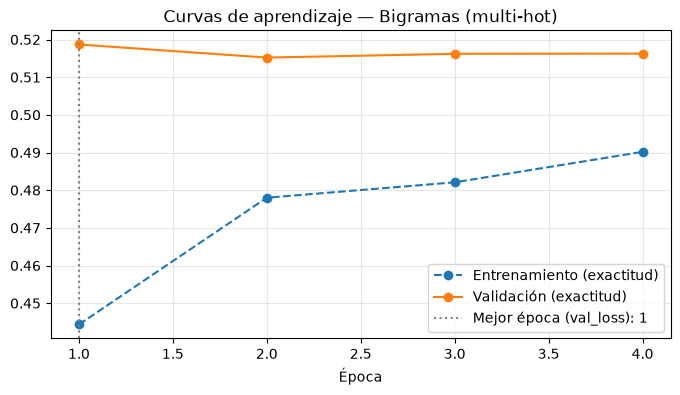

In [7]:
def modelo_denso(dim_entrada, nombre, dim_oculta=16):
    entradas = keras.Input(shape=(dim_entrada,), name="multi_hot")
    x = layers.Dense(dim_oculta, activation="relu")(entradas)
    x = layers.Dropout(0.5)(x)
    salidas = layers.Dense(N_CLASES, activation="softmax")(x)
    return keras.Model(entradas, salidas, name=nombre)


modelo_bi = modelo_denso(vec_bi.vocabulary_size(), "bigramas")
modelo_bi.summary()
hist_bi = entrenar_texto("Bigramas (multi-hot)", modelo_bi, train_bi, val_bi, test_bi, familia="Conjunto")

## 3. Modelo
**Embedding + Bi-LSTM** del Bloque 5, con las mismas reglas que los bigramas: la misma división con semilla, el vocabulario de 30,000 palabras construido solo con el entrenamiento y la prueba usada una sola vez.

| Capa | Salida |
|---|---|
| Entrada: índices | (lote, 120) |
| `Embedding(30,000, 64)` | (lote, 120, 64) |
| `Bidirectional(LSTM(32))` | (lote, 64) |
| `Dropout(0.5)` + `Dense(5, softmax)` | (lote, 5) = probabilidad de cada número de estrellas |

Como en la práctica, se entrena **sin máscara** (`mask_zero=False`): con PyTorch, la máscara desactiva cuDNN y cada época tardaría muchísimo más. La red aprende a ignorar los ceros del relleno.

Model: "bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ indices (InputLayer)            │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_palabras (Embedding)  │ (None, None, 64)       │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,945,157 (7.42 MB)

 Trainable params: 1,945,157 (7.42 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (14 outputs left out)

5000/5000 - 47s - 9ms/step - accuracy: 0.6278 - loss: 0.9108 - val_accuracy: 0.5311 - val_loss: 1.1021


Epoch 8: early stopping


Restoring model weights from the end of the best epoch: 5.



Embedding + Bi-LSTM: exactitud de validación 0.537 · de PRUEBA 0.541


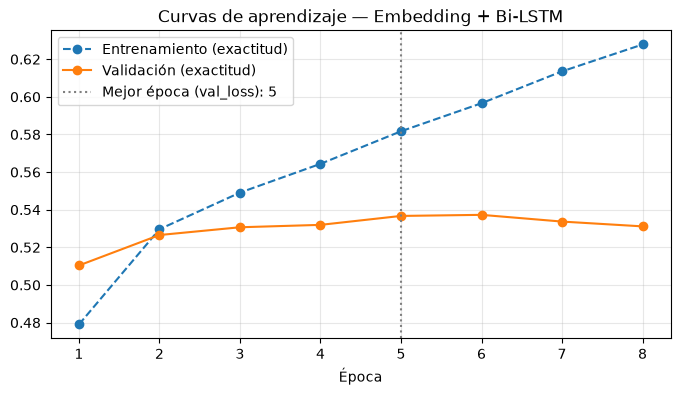

In [8]:
def modelo_bilstm(nombre, mascara=False, dim_embedding=64, unidades=32):
    entradas = keras.Input(shape=(None,), dtype="int64", name="indices")
    x = layers.Embedding(vec_seq.vocabulary_size(), dim_embedding, mask_zero=mascara, name="embedding_palabras")(entradas)
    x = layers.Bidirectional(layers.LSTM(unidades))(x)
    x = layers.Dropout(0.5)(x)
    salidas = layers.Dense(N_CLASES, activation="softmax")(x)
    return keras.Model(entradas, salidas, name=nombre)


keras.utils.set_random_seed(SEED)
modelo_seq = modelo_bilstm("bilstm")
modelo_seq.summary()
hist_seq = entrenar_texto("Embedding + Bi-LSTM", modelo_seq, train_seq, val_seq, test_seq, familia="Secuencia")

## 4. Resultados
Exactitud de **prueba** de los dos modelos. Como referencia, el azar con 5 clases balanceadas da 20 %.

In [9]:
resultados = pd.DataFrame(registro).T.sort_values("Exactitud prueba", ascending=False)
resultados[["Exactitud val", "Exactitud prueba", "Seg/época"]] = resultados[["Exactitud val", "Exactitud prueba", "Seg/época"]].astype(float).round(4)
resultados[["Parámetros", "Épocas"]] = resultados[["Parámetros", "Épocas"]].astype(int)

ganador = resultados.index[0]
familia_ganadora = resultados.loc[ganador, "Familia"]
diferencia = resultados["Exactitud prueba"].iloc[0] - resultados["Exactitud prueba"].iloc[1]
print(f"Ganador en prueba: {ganador} ({familia_ganadora}), por {diferencia * 100:.1f} puntos")
resultados

Ganador en prueba: Embedding + Bi-LSTM (Secuencia), por 1.4 puntos


,Familia,Exactitud val,Exactitud prueba,Parámetros,Épocas,Seg/época
Embedding + Bi-LSTM,Secuencia,0.5367,0.5412,1945157,8,47.3613
Bigramas (multi-hot),Conjunto,0.5187,0.5274,480101,4,56.7087


## 5. Conclusión
**¿Se cumplió la regla del cociente?**

In [10]:
prediccion = "Conjunto" if cociente < 1500 else "Secuencia"
print(f"Cociente: {cociente:,.0f} → la regla predice: {prediccion} · ganó: {familia_ganadora} ({ganador})")
print("→ La regla", "SE CUMPLIÓ" if prediccion == familia_ganadora else "NO se cumplió")

# Intervalo aproximado de la exactitud con 5,000 reseñas de prueba (error estándar de una proporción)
for nombre, fila in resultados.iterrows():
    p = fila["Exactitud prueba"]
    print(f"{nombre:22s} {p:.3f} ± {1.96 * np.sqrt(p * (1 - p) / len(y_test)):.3f} (IC 95 %)")

Cociente: 7,273 → la regla predice: Secuencia · ganó: Secuencia (Embedding + Bi-LSTM)
→ La regla SE CUMPLIÓ
Embedding + Bi-LSTM    0.541 ± 0.014 (IC 95 %)
Bigramas (multi-hot)   0.527 ± 0.014 (IC 95 %)


**¿Qué errores comete el mejor modelo?** Matriz de confusión en prueba y las reseñas en que se equivocó **con más seguridad**.

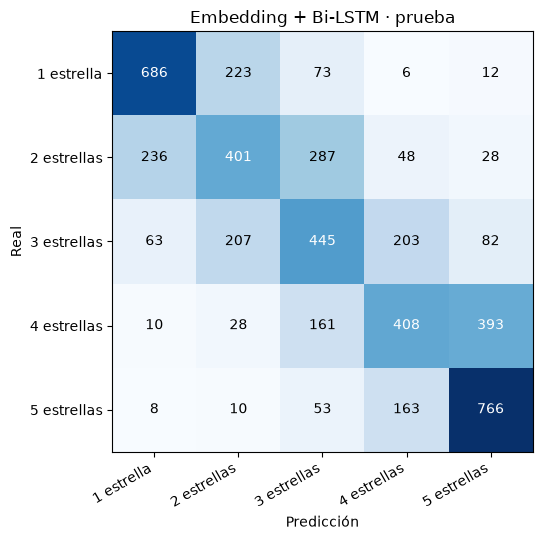

Errores: 2,294 de 5,000 (45.9%)
  a una estrella de distancia: 1,873 (81.6% de los errores)
  a dos o más estrellas:       421 (18.4% de los errores)
Exactitud por clase: {'1 estrella': 0.686, '2 estrellas': 0.401, '3 estrellas': 0.445, '4 estrellas': 0.408, '5 estrellas': 0.766}
Exactitud «sentido amplio» (negativa 1-2, neutra 3, positiva 4-5): 0.744


In [11]:
modelo_mejor = modelo_seq if familia_ganadora == "Secuencia" else modelo_bi
ds_mejor = test_seq if familia_ganadora == "Secuencia" else test_bi
probs = modelo_mejor.predict(ds_mejor, verbose=0)
pred = probs.argmax(axis=1)

M = confusion_matrix(y_test, pred, labels=range(N_CLASES))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(M, cmap="Blues")
ax.set_xticks(range(N_CLASES), CLASES, rotation=30, ha="right")
ax.set_yticks(range(N_CLASES), CLASES)
for i in range(N_CLASES):
    for j in range(N_CLASES):
        ax.text(j, i, M[i, j], ha="center", va="center", color="white" if M[i, j] > M.max() / 2 else "black")
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title(f"{ganador} · prueba")
ax.grid(False)
plt.tight_layout()
plt.show()

distancia = np.abs(pred - y_test)
errores = distancia > 0
print(f"Errores: {errores.sum():,} de {len(y_test):,} ({errores.mean():.1%})")
print(f"  a una estrella de distancia: {(distancia == 1).sum():,} ({(distancia == 1).sum() / errores.sum():.1%} de los errores)")
print(f"  a dos o más estrellas:       {(distancia >= 2).sum():,} ({(distancia >= 2).sum() / errores.sum():.1%} de los errores)")
print("Exactitud por clase:", {CLASES[c]: round(float(np.mean(pred[y_test == c] == c)), 3) for c in range(N_CLASES)})
print(f"Exactitud «sentido amplio» (negativa 1-2, neutra 3, positiva 4-5): {np.mean(np.digitize(pred, [2, 3]) == np.digitize(y_test, [2, 3])):.3f}")

In [12]:
tabla_errores = pd.DataFrame({
    "Reseña": x_test,
    "Real": [CLASES[c] for c in y_test],
    "Predicción": [CLASES[c] for c in pred],
    "Seguridad": probs.max(axis=1).round(2),
    "Distancia": distancia,
})
# Los 10 errores más seguros a 2 o más estrellas y 5 errores típicos entre estrellas vecinas
graves = tabla_errores[tabla_errores["Distancia"] >= 2].sort_values("Seguridad", ascending=False).head(10)
vecinos = tabla_errores[tabla_errores["Distancia"] == 1].sort_values("Seguridad", ascending=False).head(5)
print(f"Errores graves (2 o más estrellas), los más seguros:")
display(graves)
print("Errores entre estrellas vecinas, los más seguros:")
display(vecinos)

Errores graves (2 o más estrellas), los más seguros:


,Reseña,Real,Predicción,Seguridad,Distancia
2776,"Mala calidad, solo funciona la mitad, nada recomendable",3 estrellas,1 estrella,0.97,2
2550,"Me ha encantado, es súper comoda Mi bebe tiene 9 meses, y es perfecta para ella, y muy segura. Va contenta cuando la paseo.",3 estrellas,5 estrellas,0.95,2
2185,Aun no me ha llegado el producto. A pesar del pago de envío urgente. Imposible ponerme en contacto con Seur ni con ustedes. Ruego solucionen el problema. Gracias.,3 estrellas,1 estrella,0.94,2
1354,"Lo compré por que mi hijo se lo pasa genial en uno que parece mas sencillo de otra marca en casa de la abuela. Este ha durado dos días, el de la casa de la abuela ha aguantado todo el verano y se ...",2 estrellas,5 estrellas,0.92,3
2856,Buenos materiales. Gran sonido. Sin problemas de conexión con ningún dispositivo Bluetooth que he probado. Los leds le dan un toque chic.,3 estrellas,5 estrellas,0.91,2
4326,"No llegó el paquete, informé al vendedor y tuve respuesta inmediata para darme solución.",5 estrellas,1 estrella,0.90,4
3227,"El producto de 10. El envío pésimo, ya que dejar un paquete en un buzón de exterior de una casa cuando está lloviendo a mares. Os podéis imaginar el resultado. Nefasto por parte de la empresa de t...",4 estrellas,1 estrella,0.89,3
2752,"Son corrientes. Varios rotos, con agujero, y casi todos se desinchan al cabo de 2 horas. El brillo del anuncio no es real. Muy descontento con el producto. Asegura vendedor que incrementará su con...",3 estrellas,1 estrella,0.89,2
2234,"Menos mal que vi otra opinion pues le puse jabón liquido que sale en espuma de mercadona uno de melon y nada no funcionaba,lo quite y puse jabón normal y tampoco,al final funciona si pones un terc...",3 estrellas,1 estrella,0.88,2
2847,"Hola Me habéis cobrado 1€ y no se porque Ya que también se habéis cobrado los 3,60 que es el valor de los auriculares",3 estrellas,1 estrella,0.87,2


Errores entre estrellas vecinas, los más seguros:


,Reseña,Real,Predicción,Seguridad,Distancia
1706,"No puedo valorar el producto, nunca llego a destino",2 estrellas,1 estrella,0.98,1
1630,Nunca llego el pedido contacte con el comprador y dijo que la empresa de transportes lo perdio. Por suerte me reembolso el dinero sin más. En este aspecto de comunicación con el vendedor estoy con...,2 estrellas,1 estrella,0.98,1
1776,"Es de malisima calidad, la talla no coincide, es demaciado pequeño y feo. Una decepsion total. No lo recmiendo comprar, no es mucho dinero, pero es tirar dinero a la basura. Y tarda mas de un mes ...",2 estrellas,1 estrella,0.97,1
1558,"Pues no puedo valorarlo todavía, aún no lo he recibido. Ya vamos con tres días de retraso. Esperaré a ver que pasa.",2 estrellas,1 estrella,0.96,1
3655,"excelente producto, elimina todo los olores y dar un ambiente fresco y limpio . Muy recomendado y relación calidad precio perfecto",4 estrellas,5 estrellas,0.95,1


**¿Se cumplió la regla del cociente? Sí.** El cociente es 160,000 / 22 = 7,273, muy por encima de 1,500, y ganó el modelo de secuencia. Embedding + Bi-LSTM logró **54.1 %** de exactitud en prueba, contra **52.7 %** de los bigramas. También se cumplió la segunda parte de mi predicción: la ventaja es **pequeña**, de 1.4 puntos.

**¿La diferencia es real?** Con 5,000 reseñas de prueba, cada exactitud tiene un intervalo de ±1.4 puntos (95 %), así que en prueba los intervalos se tocan y la diferencia está al límite del ruido. Hay dos señales de que no es casualidad. La validación, con 40,000 reseñas, da la misma ventaja (53.7 % contra 51.9 %). Y las curvas muestran que los bigramas tocaron su mejor pérdida de validación en la **primera época** y ya no mejoraron: con 30,000 *n*-gramas y una capa de 16 neuronas no les cabe más. La Bi-LSTM siguió mejorando hasta la época 5. Es el caso contrario a IMDb (cociente ≈ 114): hay muchas reseñas cortas, y con eso la red sí tiene datos para aprender el orden («no es malo», «bueno, pero…»). El precio es que tiene cuatro veces más parámetros (1.95 M contra 0.48 M).

**¿Qué errores comete el mejor modelo?** Se equivoca en 2,294 de las 5,000 reseñas de prueba (45.9 %), pero la mayoría de esos errores son leves:

1. **Estrellas vecinas: el 81.6 % de los errores.** Las clases extremas son las más fáciles: acierta el 68.6 % de las reseñas de 1 estrella y el 76.6 % de las de 5. Las intermedias rondan el 40 % (2 estrellas: 40.1 %; 3: 44.5 %; 4: 40.8 %). Si solo se pregunta si la reseña es negativa (1-2), neutra (3) o positiva (4-5), la exactitud sube a **74.4 %**. Un ejemplo es la #3655: «excelente producto… Muy recomendado y relación calidad precio perfecto» tiene 4 estrellas y el modelo dijo 5. Con ese texto, ningún modelo puede saber que le faltó una estrella.
2. **Producto que no llegó.** Las reseñas #1706 («No puedo valorar el producto, nunca llegó a destino»), #1558 («aún no lo he recibido») y #2185 («Aún no me ha llegado el producto») tienen 2 o 3 estrellas, y el modelo dijo 1 estrella con 94-98 % de seguridad. Aquí cada persona calificó de forma arbitraria algo que ni siquiera recibió, y el modelo se va a lo más negativo.
3. **Reseñas mixtas: producto contra envío.** La #3227 («El producto de 10. El envío pésimo… Nefasto») tiene 4 estrellas y el modelo dijo 1: la queja final, más larga y con palabras más fuertes, pesó más que «de 10». La #4326 («No llegó el paquete, informé al vendedor y tuve respuesta inmediata») tiene **5 estrellas**: el cliente premió la atención del vendedor, y el modelo dijo 1 por «no llegó el paquete».
4. **Comparaciones.** La #1354 elogia el juguete de otra marca («mi hijo se lo pasa genial en uno… de otra marca») para criticar el comprado («este ha durado dos días»). Tiene 2 estrellas y el modelo dijo 5. Es el error de referencia que la Práctica 4 señalaba en las bolsas de palabras, y la Bi-LSTM, aunque lee en orden, tampoco lo resuelve: no sabe a qué producto se refiere cada elogio.
5. **Etiquetas que no coinciden con el texto.** La #2776 («Mala calidad, solo funciona la mitad, nada recomendable») tiene 3 estrellas y el modelo dijo 1 con 97 % de seguridad. Por el texto, el modelo tiene razón; lo inconsistente es la etiqueta. Como en IMDb, los errores más seguros encuentran casos donde el que se equivoca es el dataset.

**En resumen:** la regla acertó en qué familia gana, pero con 5 clases el techo lo pone la tarea, no el modelo. La mayoría de los errores están entre estrellas vecinas o en reseñas cuya calificación no se deduce del texto. Un Transformer preentrenado (Práctica 5) podría mejorar los casos de comparación y de reseñas mixtas, pero no los de las etiquetas arbitrarias.